# BÀI TẬP LỚN 2 COMPUTER VISION
## Gradient Domain Editing và Ghép ảnh toàn cảnh (Panoramic Photos - Image Stitching)

Notebook gồm hai phần chính:

| Phần | Nội dung |
|---|---|
| **Phần 1** | Gradient Domain Editing (Poisson Blending) và so sánh với ghép trực tiếp (baseline) |
| **Phần 2** | Ghép ảnh toàn cảnh dựa trên đặc trưng: **SIFT** và **ORB** trên cùng một pipeline, chạy trên nhiều bộ ảnh |

### Mục lục
0. Hướng dẫn chạy & cấu trúc dữ liệu
1. Thiết lập môi trường
2. Nạp dữ liệu (có chế độ ảnh DEMO dự phòng)
3. **PHẦN 1** – Gradient Domain Editing: lý thuyết, mask, baseline, Poisson blending, so sánh, phân tích
4. **PHẦN 2** – Panorama: tiền xử lý, trích đặc trưng, matching, homography, warping, blending, pipeline hoàn chỉnh
5. Thực nghiệm trên nhiều bộ ảnh (SIFT vs ORB)
6. Phân tích, đánh giá & kết luận
7. Xuất kết quả & kiểm tra

### Hướng dẫn chạy
1. Đặt `USE_GOOGLE_DRIVE` ở mục 1 (True nếu dùng Drive, False nếu upload trực tiếp vào runtime).
2. Nếu, truy cập vào folder [DIPCV_BTL2](https://drive.google.com/drive/folders/13EJDOSFz_w_9IDo96--RbzkETjIoADIq?usp=drive_link) để tải ảnh về và upload ảnh theo cấu trúc bên dưới.
3. **Runtime -> Run all**.

### Cấu trúc thư mục dữ liệu
```
DIPCV_BTL2/
└── data/
    ├── gradient/
    │   ├── background.jpg     # ảnh nền
    │   ├── source.jpg         # ảnh chứa đối tượng cần ghép
    │   └── mask.png           # (tuỳ chọn) mask trắng-đen; nếu không có sẽ dùng GrabCut
    ├── pano_set1/             # bộ ảnh mẫu của đề (đặt tên theo thứ tự TRÁI -> PHẢI)
    │   ├── 01.jpg  02.jpg  03.jpg ...
    └── pano_set2/             # bộ ảnh tự chụp/tìm thêm (cùng quy ước)
        ├── 01.jpg  02.jpg  03.jpg ...
```
> Nếu thiếu file, notebook tự sinh **ảnh DEMO** (có nhãn rõ ràng) để kiểm tra kỹ thuật. Kết quả DEMO **không dùng để nộp**.
> Ảnh panorama được sắp xếp theo **tên file** và giả định thứ tự tên file = thứ tự từ trái sang phải.

## 1. Thiết lập môi trường

In [ ]:
from pathlib import Path
import math
import shutil
import time

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.sparse.linalg import splu
from IPython.display import display

plt.rcParams.update({'figure.figsize': (15, 8), 'axes.titlesize': 10, 'figure.dpi': 100})
np.random.seed(42)
cv2.setRNGSeed(42)

# ---- Cấu hình chung ---------------------------------------------------------
USE_GOOGLE_DRIVE = True     # True nếu dùng Google Drive: MyDrive/DIPCV_BTL2/

if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive/')
    PROJECT_DIR = Path('/content/drive/MyDrive/DIPCV_BTL2')
else:
    PROJECT_DIR = Path('/content/DIPCV_BTL2')

DATA_DIR      = PROJECT_DIR / 'data'
GRADIENT_DIR  = DATA_DIR / 'gradient'
PANO_DIRS     = {'pano_set1': DATA_DIR / 'pano_set1',
                 'pano_set2': DATA_DIR / 'pano_set2'}
OUTPUT_DIR    = PROJECT_DIR / 'outputs'
DEMO_DIR      = PROJECT_DIR / 'demo_images_NOT_FOR_SUBMISSION'

for d in [GRADIENT_DIR, *PANO_DIRS.values(), OUTPUT_DIR, DEMO_DIR]:
    d.mkdir(parents=True, exist_ok=True)

SUPPORTED_EXTENSIONS = {'.jpg', '.jpeg', '.png'}
MAX_SIDE = 1000     # giảm kích thước ảnh lớn để giảm thời gian tính toán

print('PROJECT_DIR:', PROJECT_DIR)
print('OpenCV     :', cv2.__version__)
print('SIFT khả dụng:', hasattr(cv2, 'SIFT_create'))

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).
PROJECT_DIR: /content/drive/MyDrive/DIPCV_BTL2
OpenCV     : 4.14.0
SIFT khả dụng: True


### 1.1 Hàm tiện ích dùng chung

In [ ]:
def resize_if_needed(rgb, max_side=MAX_SIDE):
    """Giảm ảnh quá lớn nhưng giữ nguyên tỉ lệ khung hình."""
    h, w = rgb.shape[:2]
    scale = min(1.0, max_side / max(h, w))
    if scale < 1.0:
        rgb = cv2.resize(rgb, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    return rgb


def load_rgb(path, max_side=MAX_SIDE):
    """Đọc ảnh bằng OpenCV (BGR) và trả về RGB uint8."""
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if bgr is None:
        raise ValueError(f'Không đọc được ảnh: {path}')
    return resize_if_needed(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB), max_side)


def list_images(folder):
    """Liệt kê ảnh trong thư mục, sắp xếp theo tên file."""
    return sorted(p for p in Path(folder).glob('*') if p.suffix.lower() in SUPPORTED_EXTENSIONS)


def save_figure(fig, filename, dpi=150):
    path = OUTPUT_DIR / filename
    fig.savefig(path, dpi=dpi, bbox_inches='tight')
    return path


def show_grid(items, columns=3, save_name=None, figsize=None):
    """Hiển thị list (title, image) theo lưới và tùy chọn lưu figure."""
    rows = math.ceil(len(items) / columns)
    figsize = figsize or (6 * columns, 4.2 * rows)
    fig, axes = plt.subplots(rows, columns, figsize=figsize)
    axes = np.atleast_1d(axes).ravel()
    for ax, (title, img) in zip(axes, items):
        if img.ndim == 2:
            ax.imshow(img, cmap='gray', vmin=0, vmax=255)
        else:
            ax.imshow(img)
        ax.set_title(title)
        ax.axis('off')
    for ax in axes[len(items):]:
        ax.axis('off')
    fig.tight_layout()
    if save_name:
        save_figure(fig, save_name)
    plt.show()

## 2. Nạp dữ liệu

**Đầu ra của mục này**
1. Cặp ảnh cho Gradient Domain Editing (`background`, `source`).
2. Hai bộ ảnh panorama (`pano_set1`, `pano_set2`).
3. Bảng metadata và trạng thái đầu vào (`REAL` / `DEMO`).

> **Chế độ dự phòng:** file nào thiếu sẽ được thay bằng ảnh DEMO tự sinh, có nhãn `DEMO` trực tiếp trên ảnh.

In [ ]:
# ---------------- Sinh ảnh DEMO (chỉ dùng khi thiếu dữ liệu thật) ----------------
def make_demo_gradient_pair(height=400, width=600):
    """Sinh ảnh nền và ảnh nguồn demo."""
    y, x = np.mgrid[0:height, 0:width]
    bg = np.zeros((height, width, 3), np.uint8)
    bg[..., 0] = np.clip(40 + 90 * (y / height), 0, 255)
    bg[..., 1] = np.clip(60 + 50 * (y / height), 0, 255)
    bg[..., 2] = np.clip(120 - 60 * (y / height), 0, 255)
    bg[int(height * 0.65):] = (30, 90, 60)
    noise = np.random.default_rng(1).normal(0, 6, bg.shape)
    bg = np.clip(bg + noise, 0, 255).astype(np.uint8)
    cv2.putText(bg, 'DEMO background', (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 0, 255), 2, cv2.LINE_AA)

    sh, sw = 260, 300
    src = np.full((sh, sw, 3), (235, 235, 245), np.uint8)             # nền sáng trắng
    yy, xx = np.mgrid[0:sh, 0:sw]
    r = np.sqrt((xx - sw / 2) ** 2 + (yy - sh / 2) ** 2)
    ball = np.stack([255 - r * 0.9, 170 - r * 0.6, 40 + r * 0.3], -1)
    disk = r < 100
    src[disk] = np.clip(ball[disk], 0, 255).astype(np.uint8)
    cv2.putText(src, 'DEMO', (95, 140), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 0, 255), 2, cv2.LINE_AA)
    mask = (disk * 255).astype(np.uint8)
    return bg, src, mask


def make_demo_scene(seed, width=1500, height=520):
    """Cảnh rộng nhiều texture để SIFT/ORB có đủ đặc trưng."""
    rng = np.random.default_rng(seed)
    y, x = np.mgrid[0:height, 0:width]
    scene = np.stack([120 + 60 * np.sin(x / 210.0 + seed), 140 + 50 * np.cos(y / 90.0),
                      150 + 40 * np.sin((x + y) / 260.0)], -1)
    scene = np.clip(scene, 0, 255).astype(np.uint8)
    for _ in range(420):
        c = tuple(int(v) for v in rng.integers(20, 240, 3))
        px, py = int(rng.integers(0, width)), int(rng.integers(0, height))
        kind = rng.integers(0, 3)
        if kind == 0:
            cv2.circle(scene, (px, py), int(rng.integers(6, 34)), c, -1)
        elif kind == 1:
            cv2.rectangle(scene, (px, py), (px + int(rng.integers(10, 60)), py + int(rng.integers(10, 60))), c, -1)
        else:
            cv2.line(scene, (px, py), (px + int(rng.integers(-60, 60)), py + int(rng.integers(-60, 60))), c, 2)
    for i in range(30):
        cv2.putText(scene, f'{seed}-{i}', (int(rng.integers(0, width - 80)), int(rng.integers(20, height))),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2, cv2.LINE_AA)
    scene = np.clip(scene.astype(np.float32) + rng.normal(0, 5, scene.shape), 0, 255).astype(np.uint8)
    return cv2.GaussianBlur(scene, (3, 3), 0)


def make_demo_panorama(seed, n_images, view_w=640, step=380):
    """Cắt các khung nhìn chồng lấn (~40%) + lệch phối cảnh nhẹ + đổi phơi sáng."""
    scene = make_demo_scene(seed, width=step * (n_images - 1) + view_w + 60)
    H, W = scene.shape[:2]
    imgs = []
    for i in range(n_images):
        x0 = 30 + i * step
        crop = scene[:, x0:x0 + view_w].copy()
        h, w = crop.shape[:2]
        jitter = np.random.default_rng(seed * 10 + i).uniform(-12, 12, (4, 2)).astype(np.float32)
        src_pts = np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]])
        crop = cv2.warpPerspective(crop, cv2.getPerspectiveTransform(src_pts, src_pts + jitter), (w, h),
                                   borderMode=cv2.BORDER_REFLECT)
        crop = np.clip(crop.astype(np.float32) * (0.9 + 0.08 * i), 0, 255).astype(np.uint8)
        cv2.putText(crop, f'DEMO {seed}-{i + 1}', (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 0, 255), 2, cv2.LINE_AA)
        imgs.append(crop)
    return imgs


def save_rgb(path, rgb):
    cv2.imwrite(str(path), cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR))

Đã tìm thấy ảnh Gradient Domain.
Đã tìm thấy 4 ảnh thật trong pano_set1: ['boat1.jpg', 'boat2.jpg', 'boat3.jpg', 'boat4.jpg']
Đã tìm thấy 6 ảnh thật trong pano_set2: ['budapest1.jpg', 'budapest2.jpg', 'budapest3.jpg', 'budapest4.jpg', 'budapest5.jpg', 'budapest6.jpg']


,nhóm,file,w,h,kênh,input_status
0,gradient,background,1000,562,3,REAL
1,gradient,source,500,500,3,REAL
2,pano_set1,ảnh 1,1000,667,3,REAL (4 ảnh)
3,pano_set1,ảnh 2,1000,667,3,REAL (4 ảnh)
4,pano_set1,ảnh 3,1000,667,3,REAL (4 ảnh)
5,pano_set1,ảnh 4,1000,667,3,REAL (4 ảnh)
6,pano_set2,ảnh 1,1000,706,3,REAL (6 ảnh)
7,pano_set2,ảnh 2,1000,706,3,REAL (6 ảnh)
8,pano_set2,ảnh 3,1000,706,3,REAL (6 ảnh)
9,pano_set2,ảnh 4,1000,709,3,REAL (6 ảnh)


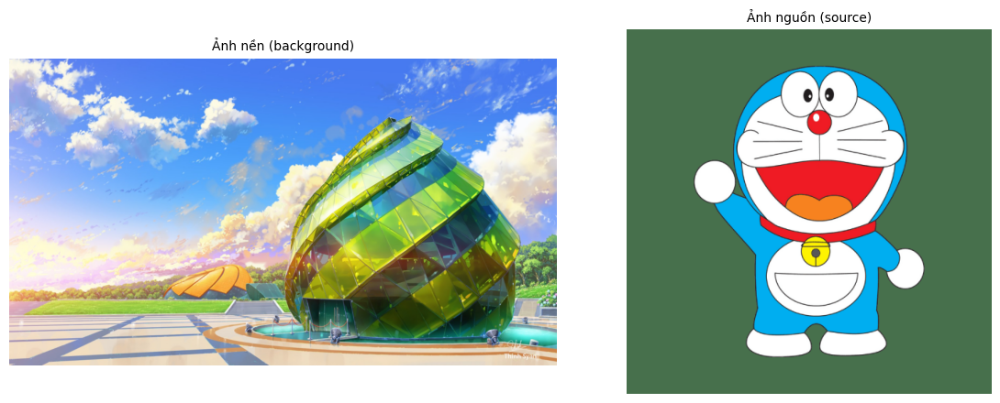

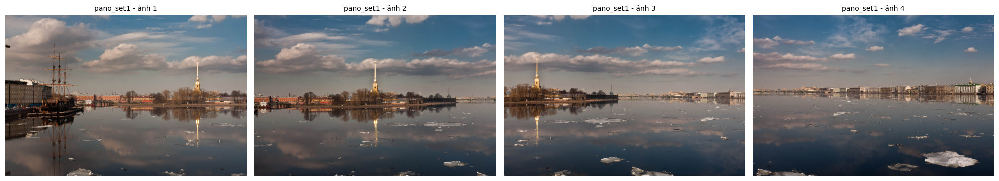

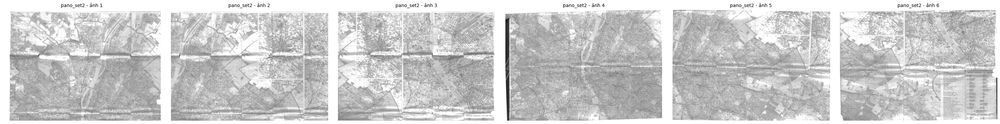

In [ ]:
input_status = {}

# ---- (a) Gradient Domain Editing ----
bg_path, src_path, mask_path = (GRADIENT_DIR / 'background.jpg', GRADIENT_DIR / 'source.jpg',
                                GRADIENT_DIR / 'mask.png')
GRADIENT_IS_DEMO = not (bg_path.exists() and src_path.exists())
if GRADIENT_IS_DEMO:
    demo_bg, demo_src, demo_mask = make_demo_gradient_pair()
    bg_path, src_path, mask_path = (DEMO_DIR / 'background.jpg', DEMO_DIR / 'source.jpg', DEMO_DIR / 'mask.png')
    save_rgb(bg_path, demo_bg); save_rgb(src_path, demo_src); cv2.imwrite(str(mask_path), demo_mask)
    input_status['gradient'] = 'DEMO — thiếu background.jpg/source.jpg'
    print('CẢNH BÁO: thiếu ảnh Gradient Domain -> dùng ảnh DEMO.')
else:
    input_status['gradient'] = 'REAL'
    print('Đã tìm thấy ảnh Gradient Domain.')

background = load_rgb(bg_path)
source = load_rgb(src_path, max_side=500)      # ảnh nguồn nhỏ hơn để hệ Poisson nhẹ

# ---- (b) Panorama ----
pano_sets = {}
for set_name, folder in PANO_DIRS.items():
    files = list_images(folder)
    if len(files) >= 2:
        pano_sets[set_name] = [load_rgb(f) for f in files]
        input_status[set_name] = f'REAL ({len(files)} ảnh)'
        print(f'Đã tìm thấy {len(files)} ảnh thật trong {set_name}: {[f.name for f in files]}')
    else:
        # Dự phòng ảnh DEMO nếu chưa có đủ ảnh
        demo_folder = DEMO_DIR / set_name
        demo_folder.mkdir(exist_ok=True)
        demo_imgs = make_demo_panorama(seed=11, n_images=4)
        for i, im in enumerate(demo_imgs):
            save_rgb(demo_folder / f'{i + 1:02d}.jpg', im)
        files = list_images(demo_folder)
        pano_sets[set_name] = [load_rgb(f) for f in files]
        input_status[set_name] = f'DEMO ({len(files)} ảnh) — thiếu dữ liệu thật'
        print(f'CẢNH BÁO: {set_name} thiếu ảnh (cần >= 2) -> dùng ảnh DEMO.')

# ---- Bảng metadata ----
rows = [{'nhóm': 'gradient', 'file': 'background', 'w': background.shape[1], 'h': background.shape[0],
         'kênh': background.shape[2], 'input_status': input_status['gradient']},
        {'nhóm': 'gradient', 'file': 'source', 'w': source.shape[1], 'h': source.shape[0],
         'kênh': source.shape[2], 'input_status': input_status['gradient']}]
for set_name, imgs in pano_sets.items():
    for i, im in enumerate(imgs):
        rows.append({'nhóm': set_name, 'file': f'ảnh {i + 1}', 'w': im.shape[1], 'h': im.shape[0],
                     'kênh': im.shape[2], 'input_status': input_status[set_name]})
manifest_df = pd.DataFrame(rows)
display(manifest_df)

show_grid([('Ảnh nền (background)', background), ('Ảnh nguồn (source)', source)],
          columns=2, figsize=(12, 4.5), save_name='00_gradient_inputs.png')
for set_name, imgs in pano_sets.items():
    show_grid([(f'{set_name} - ảnh {i + 1}', im) for i, im in enumerate(imgs)],
              columns=len(imgs), figsize=(5 * len(imgs), 3.6), save_name=f'00_{set_name}_inputs.png')

# PHẦN 1 — GRADIENT DOMAIN EDITING

## 3. Bài toán và nguyên lý

**Bài toán.** Cho ảnh nguồn $S$, ảnh nền $B$ và vùng đối tượng $\Omega$ (mask). Cần dán $\Omega$ vào $B$ sao cho *không thấy đường nối* và *ánh sáng hòa hợp với nền*.

**Vấn đề của ghép trực tiếp (copy-paste).** Mắt người nhạy với **gradient** (thay đổi cường độ) hơn là giá trị tuyệt đối. Copy nguyên pixel làm xuất hiện gradient giả rất lớn dọc biên $\partial\Omega$ vì màu nền của hai ảnh khác nhau.

**Poisson Blending (Pérez et al., 2003).** Tìm ảnh $f$ trong $\Omega$ sao cho **gradient của $f$ gần nhất với trường hướng dẫn $\mathbf{v}$** (gradient của ảnh nguồn), trong khi **giá trị tại biên** khớp với ảnh nền $f^*$:

$$\min_f \iint_\Omega \|\nabla f-\mathbf v\|^2 \quad\text{với}\quad f|_{\partial\Omega}=f^*|_{\partial\Omega}$$

Nghiệm thỏa phương trình Poisson $\Delta f=\operatorname{div}\mathbf v$ trong $\Omega$. Rời rạc hóa trên lưới pixel (láng giềng 4 hướng $N_p$), với mỗi pixel $p\in\Omega$:

$$|N_p|\,f_p-\sum_{q\in N_p\cap\Omega}f_q=\sum_{q\in N_p\cap\partial\Omega}f^*_q+\sum_{q\in N_p}v_{pq}$$

trong đó $v_{pq}=S_p-S_q$ (gradient ảnh nguồn) cho các cặp $(p,q)$ cùng nằm trong $\Omega$; với cặp cắt ngang biên $\partial\Omega$ (đối tượng ↔ nền của ảnh nguồn) ta đặt $v_{pq}=0$ vì đó là cạnh giả của ảnh nguồn, không thuộc đối tượng. Đây là hệ tuyến tính thưa $A\mathbf f=\mathbf b$ (mỗi kênh màu giải riêng), $A$ đối xứng, xác định dương -> giải bằng sparse solver.

**Mixing gradients (biến thể).** Chọn $v_{pq}$ là gradient có độ lớn *lớn hơn* giữa nguồn và nền: $v_{pq}=S_p-S_q$ nếu $|S_p-S_q|>|B_p-B_q|$, ngược lại lấy của nền. Giữ được texture/cạnh của nền phía sau đối tượng (hữu ích với đối tượng có nền trong suốt/viền mảnh).

## 3.1 Các bước hiện thực
1. Tạo **mask** vùng đối tượng từ ảnh nguồn.
2. Chọn **vị trí đặt** đối tượng trên ảnh nền.
3. **Baseline**: copy trực tiếp pixel trong mask.
4. Dựng hệ Poisson thưa $A\mathbf f=\mathbf b$, giải bằng `scipy.sparse.linalg` (phân rã LU một lần, dùng cho 3 kênh).
5. Ghép kết quả, so sánh với baseline (+ `cv2.seamlessClone` làm tham chiếu).

### 3.2 Tạo mask vùng đối tượng

Phương pháp tạo mask: GrabCut rect=(25, 25, 450, 450) | số pixel mask: 83017


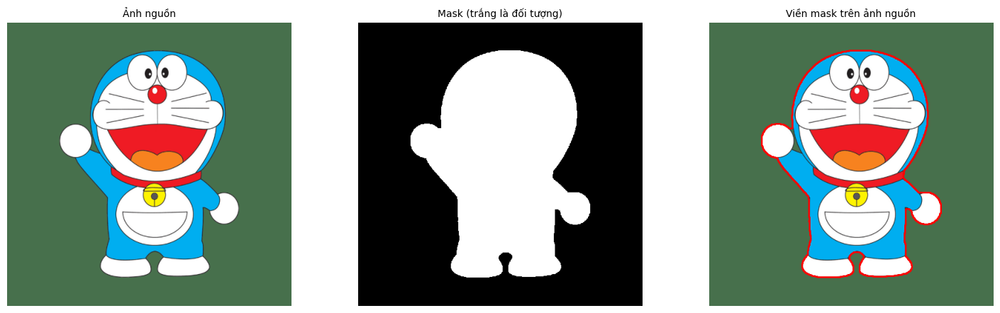

In [ ]:
# Ưu tiên: (1) mask.png do người dùng cung cấp -> (2) GrabCut với hình chữ nhật -> (3) ellipse
# Chỉnh SRC_RECT = (x, y, w, h) bao quanh đối tượng trong ảnh nguồn (đã resize) nếu dùng GrabCut.
SRC_RECT = (25, 25, 450, 450)
MASK_MODE = 'auto'        # 'auto' | 'file' | 'grabcut' | 'ellipse'


def mask_from_grabcut(rgb, rect, iters=6):
    """GrabCut khởi tạo bằng hình chữ nhật."""
    mask = np.zeros(rgb.shape[:2], np.uint8)
    bgd, fgd = np.zeros((1, 65), np.float64), np.zeros((1, 65), np.float64)
    cv2.grabCut(cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR), mask, rect, bgd, fgd, iters, cv2.GC_INIT_WITH_RECT)
    return np.where((mask == cv2.GC_FGD) | (mask == cv2.GC_PR_FGD), 255, 0).astype(np.uint8)


def clean_mask(mask):
    """Giữ thành phần liên thông lớn nhất, lấp lỗ, làm mượt biên."""
    mask = (mask > 127).astype(np.uint8) * 255
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask)
    if n > 1:
        mask = ((labels == 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])) * 255).astype(np.uint8)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled = np.zeros_like(mask)
    cv2.drawContours(filled, contours, -1, 255, -1)
    return filled


def build_mask(src_rgb, mode=MASK_MODE):
    h, w = src_rgb.shape[:2]
    if mode in ('auto', 'file') and mask_path.exists():
        m = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
        m = cv2.resize(m, (w, h), interpolation=cv2.INTER_NEAREST)
        return clean_mask(m), 'file mask.png'
    if mode in ('auto', 'grabcut'):
        rect = SRC_RECT or (int(0.05 * w), int(0.05 * h), int(0.9 * w), int(0.9 * h))
        return clean_mask(mask_from_grabcut(src_rgb, rect)), f'GrabCut rect={rect}'
    m = np.zeros((h, w), np.uint8)
    cv2.ellipse(m, (w // 2, h // 2), (w // 2 - 5, h // 2 - 5), 0, 0, 360, 255, -1)
    return m, 'ellipse'

mask, mask_method = build_mask(source)
print('Phương pháp tạo mask:', mask_method, '| số pixel mask:', int((mask > 0).sum()))

overlay = source.copy()
cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cv2.drawContours(overlay, cnts, -1, (255, 0, 0), 2)
show_grid([('Ảnh nguồn', source), ('Mask (trắng là đối tượng)', mask), ('Viền mask trên ảnh nguồn', overlay)],
          columns=3, figsize=(15, 4.5), save_name='part1_mask.png')

### 3.3 Cắt đối tượng & chọn vị trí đặt trên ảnh nền

In [ ]:
def crop_to_mask(src_rgb, mask, pad=2):
    """Cắt ảnh nguồn/mask theo bounding box của mask (+ viền pad để có vùng biên)."""
    ys, xs = np.where(mask > 0)
    y0, y1 = max(ys.min() - pad, 0), min(ys.max() + pad + 1, mask.shape[0])
    x0, x1 = max(xs.min() - pad, 0), min(xs.max() + pad + 1, mask.shape[1])
    return src_rgb[y0:y1, x0:x1].copy(), mask[y0:y1, x0:x1].copy()


src_crop, mask_crop = crop_to_mask(source, mask)

# Tự co đối tượng nếu lớn hơn khoảng 45% ảnh nền
max_h, max_w = int(0.45 * background.shape[0]), int(0.45 * background.shape[1])
s = min(1.0, max_h / src_crop.shape[0], max_w / src_crop.shape[1])
if s < 1.0:
    src_crop = cv2.resize(src_crop, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    mask_crop = cv2.resize(mask_crop, (src_crop.shape[1], src_crop.shape[0]), interpolation=cv2.INTER_NEAREST)
mask_crop = (mask_crop > 127).astype(np.uint8)

bh, bw = background.shape[:2]
ch, cw = mask_crop.shape
OFFSET = (int(0.7 * bh - ch / 2), int(0.2 * bw - cw / 2))
OFFSET = (int(np.clip(OFFSET[0], 1, bh - ch - 1)), int(np.clip(OFFSET[1], 1, bw - cw - 1)))
print('Kích thước đối tượng:', (cw, ch), '| OFFSET (y, x):', OFFSET)

Kích thước đối tượng: (200, 252) | OFFSET (y, x): (267, 100)


### 3.4 Baseline — ghép trực tiếp (copy-paste)
Sao chép pixel trong mask từ ảnh nguồn sang ảnh nền, **không** xử lý gradient hay biên. Dùng làm đối chứng.

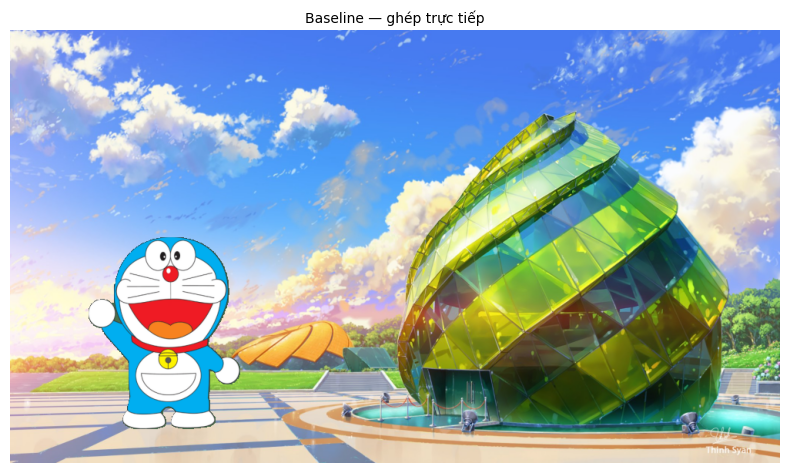

In [ ]:
def direct_paste(bg_rgb, src_crop, mask_crop, offset):
    """Baseline: copy trực tiếp pixel trong mask."""
    out = bg_rgb.copy()
    y, x = offset
    h, w = mask_crop.shape
    region = out[y:y + h, x:x + w]
    region[mask_crop > 0] = src_crop[mask_crop > 0]
    return out


direct_result = direct_paste(background, src_crop, mask_crop, OFFSET)
show_grid([('Baseline — ghép trực tiếp', direct_result)], columns=1, figsize=(8, 5.5),
          save_name='part1_direct_paste.png')

### 3.5 Poisson Blending — dựng và giải hệ phương trình thưa
Mỗi pixel trong mask là một ẩn số. Ma trận $A$ (kích thước $n\times n$, $n$ = số pixel mask) có đường chéo $|N_p|=4$ và $-1$ tại vị trí các láng giềng cũng nằm trong mask. Vế phải $\mathbf b$ chứa (i) giá trị ảnh nền ở các láng giềng nằm ngoài mask (điều kiện biên Dirichlet) và (ii) tổng gradient hướng dẫn. Vì $A$ giống nhau cho cả 3 kênh nên chỉ phân rã LU **một lần**.

In [ ]:
def poisson_blend(bg_rgb, src_crop, mask_crop, offset, mixing=False):
    """
    Poisson blending bằng sparse linear solver.
    mixing=False : trường hướng dẫn bằng gradient ảnh nguồn.
    mixing=True  : lấy gradient có độ lớn lớn hơn giữa nguồn và nền.
    """
    y0, x0 = offset
    h, w = mask_crop.shape
    bg = bg_rgb.astype(np.float64)
    src = src_crop.astype(np.float64)
    inside = mask_crop > 0

    # Đánh chỉ số cho các pixel thuộc mask
    idx = -np.ones((h, w), np.int64)
    ys, xs = np.where(inside)
    idx[ys, xs] = np.arange(len(ys))
    n = len(ys)

    rows, cols, vals = [], [], []
    b = np.zeros((n, 3))
    for k, (y, x) in enumerate(zip(ys, xs)):
        rows.append(k); cols.append(k); vals.append(4.0)
        for dy, dx in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            qy, qx = y + dy, x + dx
            # gradient hướng dẫn v_pq
            # gradient nguồn chỉ lấy cho cặp (p,q) cùng nằm trong mask; cặp cắt ngang biên mask
            inside_q = 0 <= qy < h and 0 <= qx < w and inside[qy, qx]
            g_src = src[y, x] - src[qy, qx] if inside_q else np.zeros(3)
            g_bg = bg[y0 + y, x0 + x] - bg[y0 + qy, x0 + qx]
            if mixing:
                v = g_src if np.abs(g_src).sum() > np.abs(g_bg).sum() else g_bg
            else:
                v = g_src
            b[k] += v
            if 0 <= qy < h and 0 <= qx < w and inside[qy, qx]:
                rows.append(k); cols.append(idx[qy, qx]); vals.append(-1.0)
            else:
                b[k] += bg[y0 + qy, x0 + qx]

    A = sp.csc_matrix((vals, (rows, cols)), shape=(n, n))
    lu = splu(A)
    f = np.stack([lu.solve(b[:, c]) for c in range(3)], axis=1)

    out = bg.copy()
    out[y0 + ys, x0 + xs] = f
    return np.clip(out, 0, 255).astype(np.uint8), A.shape, A.nnz


t0 = time.time()
poisson_result, A_shape, A_nnz = poisson_blend(background, src_crop, mask_crop, OFFSET, mixing=False)
t_poisson = time.time() - t0
t0 = time.time()
poisson_mix_result, _, _ = poisson_blend(background, src_crop, mask_crop, OFFSET, mixing=True)
t_poisson_mix = time.time() - t0
print(f'Hệ Poisson: A {A_shape[0]}x{A_shape[1]}, {A_nnz} phần tử khác 0 '
      f'(độ thưa {100 * (1 - A_nnz / A_shape[0] ** 2):.3f}%) | thời gian: {t_poisson:.2f}s (gradient nguồn) / {t_poisson_mix:.2f}s (mixing)')

# Tham chiếu: cài đặt sẵn của OpenCV
center = (OFFSET[1] + cw // 2, OFFSET[0] + ch // 2)
cv_clone = cv2.cvtColor(cv2.seamlessClone(cv2.cvtColor(src_crop, cv2.COLOR_RGB2BGR),
                                          cv2.cvtColor(background, cv2.COLOR_RGB2BGR),
                                          mask_crop * 255, center, cv2.NORMAL_CLONE), cv2.COLOR_BGR2RGB)

Hệ Poisson: A 32350x32350, 160654 phần tử khác 0 (độ thưa 99.985%) | thời gian: 0.95s (gradient nguồn) / 1.74s (mixing)


### 3.6 So sánh kết quả

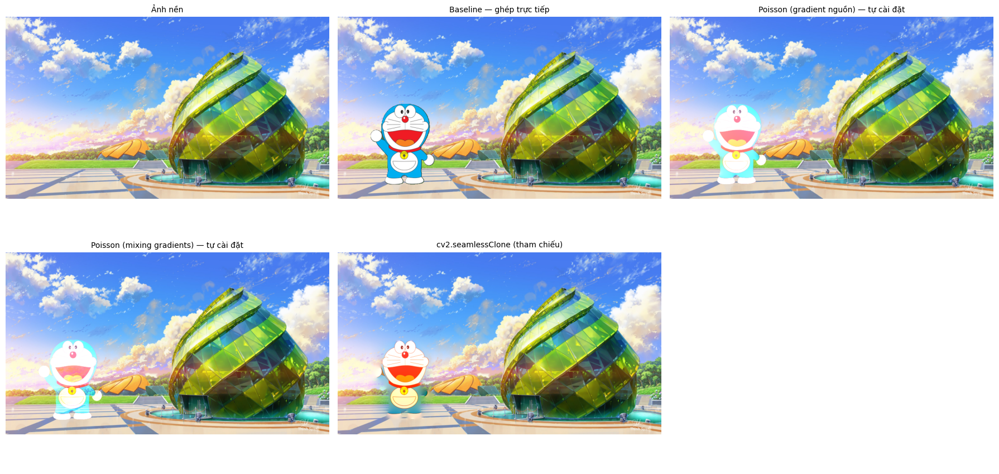

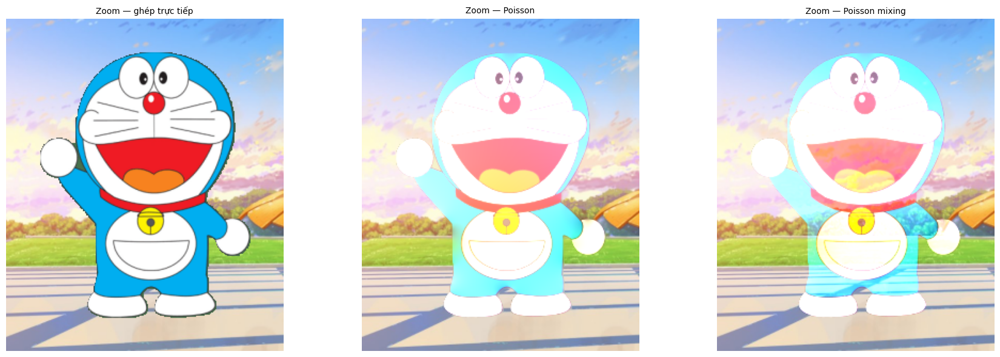

In [ ]:
show_grid([
    ('Ảnh nền', background),
    ('Baseline — ghép trực tiếp', direct_result),
    ('Poisson (gradient nguồn) — tự cài đặt', poisson_result),
    ('Poisson (mixing gradients) — tự cài đặt', poisson_mix_result),
    ('cv2.seamlessClone (tham chiếu)', cv_clone),
], columns=3, figsize=(18, 9), save_name='part1_comparison.png')

# Phóng to vùng biên để thấy rõ đường nối
pad = 30
ya, yb = max(OFFSET[0] - pad, 0), min(OFFSET[0] + ch + pad, bh)
xa, xb = max(OFFSET[1] - pad, 0), min(OFFSET[1] + cw + pad, bw)
show_grid([
    ('Zoom — ghép trực tiếp', direct_result[ya:yb, xa:xb]),
    ('Zoom — Poisson', poisson_result[ya:yb, xa:xb]),
    ('Zoom — Poisson mixing', poisson_mix_result[ya:yb, xa:xb]),
], columns=3, figsize=(18, 6), save_name='part1_comparison_zoom.png')

### 3.7 Đánh giá định lượng
Hai chỉ số đơn giản, không cần ảnh chuẩn (ground truth):

* **Seam discontinuity** – trung bình $|I_{\text{trong biên}}-I_{\text{ngoài biên}}|$ trên vành biên mask: càng nhỏ -> đường nối càng khó thấy.
* **Object color shift** – độ lệch trung bình của màu đối tượng so với ảnh nguồn gốc (Poisson chủ động đổi màu đối tượng để hòa nền; giá trị lớn nghĩa là đối tượng đã bị chỉnh sáng/màu nhiều).

In [ ]:
def seam_discontinuity(result_rgb, mask_crop, offset):
    """Sai khác trung bình giữa vành pixel trong mask sát biên và vành pixel ngoài mask sát biên."""
    y0, x0 = offset
    h, w = mask_crop.shape
    full = np.zeros(result_rgb.shape[:2], np.uint8)
    full[y0:y0 + h, x0:x0 + w] = mask_crop
    kernel = np.ones((3, 3), np.uint8)
    inner = (full > 0) & (cv2.erode(full, kernel) == 0)          # vành trong
    outer = (cv2.dilate(full, kernel) > 0) & (full == 0)          # vành ngoài
    if inner.sum() == 0 or outer.sum() == 0:
        return float('nan')
    return float(np.abs(result_rgb[inner].astype(np.float64).mean(0) - result_rgb[outer].astype(np.float64).mean(0)).mean())


def seam_edge_energy(result_rgb, mask_crop, offset):
    """Độ lớn gradient trung bình dọc biên mask (gradient giả do đường nối)."""
    y0, x0 = offset
    h, w = mask_crop.shape
    full = np.zeros(result_rgb.shape[:2], np.uint8)
    full[y0:y0 + h, x0:x0 + w] = mask_crop
    ring = cv2.morphologyEx(full, cv2.MORPH_GRADIENT, np.ones((3, 3), np.uint8)) > 0
    gray = cv2.cvtColor(result_rgb, cv2.COLOR_RGB2GRAY).astype(np.float64)
    gx, gy = cv2.Sobel(gray, cv2.CV_64F, 1, 0), cv2.Sobel(gray, cv2.CV_64F, 0, 1)
    return float(np.sqrt(gx ** 2 + gy ** 2)[ring].mean())


def object_color_shift(result_rgb, src_crop, mask_crop, offset):
    y0, x0 = offset
    h, w = mask_crop.shape
    region = result_rgb[y0:y0 + h, x0:x0 + w].astype(np.float64)
    m = mask_crop > 0
    return float(np.abs(region[m] - src_crop.astype(np.float64)[m]).mean())


gradient_rows = []
for name, res in [('Ghép trực tiếp (baseline)', direct_result), ('Poisson (gradient nguồn)', poisson_result),
                  ('Poisson (mixing gradients)', poisson_mix_result), ('cv2.seamlessClone', cv_clone)]:
    gradient_rows.append({
        'phương pháp': name,
        'seam_discontinuity': round(seam_discontinuity(res, mask_crop, OFFSET), 3),
        'seam_edge_energy': round(seam_edge_energy(res, mask_crop, OFFSET), 3),
        'object_color_shift': round(object_color_shift(res, src_crop, mask_crop, OFFSET), 3),
    })
gradient_df = pd.DataFrame(gradient_rows)
display(gradient_df)
gradient_df.to_csv(OUTPUT_DIR / 'part1_gradient_metrics.csv', index=False)

diff_own_cv = np.abs(poisson_result.astype(np.float64) - cv_clone.astype(np.float64)).mean()
print(f'Sai khác trung bình giữa Poisson tự cài đặt và cv2.seamlessClone: {diff_own_cv:.3f} (thang 0-255)')

,phương pháp,seam_discontinuity,seam_edge_energy,object_color_shift
0,Ghép trực tiếp (baseline),107.069,351.783,0.000
1,Poisson (gradient nguồn),2.941,75.726,44.185
2,Poisson (mixing gradients),2.976,78.566,44.396
3,cv2.seamlessClone,0.382,41.541,34.603


Sai khác trung bình giữa Poisson tự cài đặt và cv2.seamlessClone: 2.351 (thang 0-255)


### 3.8 Phân tích Phần 1

**Số liệu** (thang 0–255, $D_{\text{seam}}$ = `seam_discontinuity`, $E_{\text{seam}}$ = `seam_edge_energy`, $\Delta_{\text{color}}$ = `object_color_shift`; cả ba chỉ số càng nhỏ càng tốt):

| Phương pháp | $D_{\text{seam}}$ | $E_{\text{seam}}$ | $\Delta_{\text{color}}$ |
|---|---|---|---|
| Ghép trực tiếp | 107.069 | 351.783 | 0.000 |
| Poisson (gradient nguồn) | 2.941 | 75.726 | 44.185 |
| Poisson (mixing gradients) | 2.976 | 78.566 | 44.396 |
| `cv2.seamlessClone` | 0.382 | 41.541 | 34.603 |

**Nhận xét:**

* **Ghép trực tiếp** giữ nguyên màu đối tượng ($\Delta_{\text{color}} = 0$) nhưng lộ đường nối rõ nhất: $D_{\text{seam}} = 107.069$ và $E_{\text{seam}} = 351.783$, cao nhất trong bốn phương pháp. Nguyên nhân là mask nhị phân còn chứa các pixel viền pha lẫn nền xanh của ảnh nguồn, tạo viền xanh lục và răng cưa quanh nhân vật.
* **Poisson (gradient nguồn)** giảm $D_{\text{seam}}$ khoảng 36 lần (107.069 -> 2.941) và $E_{\text{seam}}$ khoảng 4.6 lần (351.783 -> 75.726). Điều này khớp với điều kiện biên Dirichlet: giá trị trên biên bằng ảnh nền nên không còn bước nhảy. $E_{\text{seam}}$ không về gần 0 vì vành biên còn chứa đường viền đen thật của nhân vật. Trade-off là $\Delta_{\text{color}}$ tăng từ 0 lên 44.185: ảnh nguồn là các mảng màu phẳng, bão hòa, còn vùng nền quanh vị trí đặt là quảng trường sáng, nhạt, nên hiệu chỉnh nội suy từ biên kéo màu nhân vật về phía nền (thân xanh dương thành xanh ngọc nhạt, miệng đỏ thành đỏ hồng, đường viền đen mờ đi).
* **Mixing gradients** gần như tương đương Poisson thường ($D_{\text{seam}}$ 2.976, $E_{\text{seam}}$ 78.566, $\Delta_{\text{color}}$ 44.396) và nhỉnh hơn một chút ở cả ba chỉ số. Lý do là gradient nguồn trong các mảng màu phẳng xấp xỉ 0 nên gradient của nền thắng thế, khiến texture nền (vệt sọc quảng trường, hình tán cây phía xa) dính vào thân và chân Doraemon. Ba chỉ số không đo được hiện tượng này, nó chỉ thấy qua quan sát hình. Với cặp ảnh này, mixing gradients không mang lại lợi ích mà còn tốn thời gian hơn (3.99 s so với 1.46 s, khoảng 2.7 lần).
* **`cv2.seamlessClone`** có cả ba chỉ số thấp hơn bản tự cài đặt ($\Delta_{\text{color}}$ 34.603, thấp hơn khoảng 22%), nhân vật Doraemon giữ màu bão hòa hơn (mũi, miệng vẫn đỏ). Tuy nhiên $D_{\text{seam}}$ và $E_{\text{seam}}$ thấp một phần vì viền đối tượng bị hòa vào nền (đầu Doraemon gần như biến mất vì cùng màu nền trời), nên chỉ số thấp hơn không đồng nghĩa với kết quả đẹp hơn ở mọi khía cạnh.
* **Về sai khác với `cv2.seamlessClone`:** sai khác trung bình 2.351 là trung bình trên cả ảnh $1000\times562$, trong khi đối tượng chỉ chiếm 32350 pixel (khoảng 5.8%). Nếu hai kết quả trùng nhau ngoài mask thì sai khác trung bình trong vùng đối tượng cỡ $2.351\times562000/32350 \approx 41$, khá lớn. Vì vậy con số 2.351 **chưa đủ** để khẳng định cài đặt tự viết trùng với OpenCV. Hai bên cùng giải một họ bài toán nhưng khác nhau đáng kể trong vùng đối tượng, nguyên nhân có khả năng nhất là cách xử lý pixel sát biên (bản tự cài đặt cho $v_{pq}=0$ với cặp cắt ngang biên mask).

**Kết luận trade-off:** Poisson blending giải quyết được điểm yếu lớn nhất của ghép trực tiếp là đường nối, nhưng đổi lại màu đối tượng bị kéo về phía nền. Không phương pháp nào tốt hơn ở mọi tiêu chí.

# PHẦN 2 — GHÉP ẢNH TOÀN CẢNH (IMAGE STITCHING)

## 4. Pipeline

```
Ảnh rời ─> Tiền xử lý ─> Feature detection & description ─> Feature matching ─> Lọc Lowe ratio
       ─> Homography + RANSAC ─> Warp về ảnh tham chiếu ─> Blending vùng chồng lấn ─> Crop viền đen ─> Panorama
```

| Bước | Vai trò |
|---|---|
| Tiền xử lý | Resize (giảm chi phí), chuyển ảnh xám (đặc trưng chỉ cần cường độ) |
| Detect + describe | Tìm điểm nổi bật *lặp lại được* giữa các ảnh và mô tả vùng lân cận bằng vector |
| Matching | Ghép điểm tương ứng giữa 2 ảnh bằng khoảng cách descriptor (L2 với SIFT, Hamming với ORB) |
| Ratio test | Loại các match mơ hồ: giữ nếu $d_1 < r\cdot d_2$ (Lowe, $r\approx0.75$) |
| Homography + RANSAC | Ước lượng $H$ (8 bậc tự do) từ các match; RANSAC loại outlier còn sót |
| Warp | Đưa tất cả ảnh về cùng hệ tọa độ (ảnh **giữa** làm tham chiếu để giảm biến dạng) |
| Blending | Trộn vùng chồng lấn để giảm seam do khác phơi sáng |
| Crop | Bỏ phần viền đen thừa |

Vì các ảnh chụp **từ cùng một vị trí, chỉ xoay camera**, quan hệ giữa hai ảnh chính xác là một homography -> cơ sở lý thuyết của pipeline.

**Cùng một pipeline cho mọi phương pháp:** chỉ hàm trích đặc trưng và loại khoảng cách matching thay đổi (`method = 'SIFT' | 'ORB'`), phần còn lại giữ nguyên để so sánh công bằng.

### 4.1 Tiền xử lý

In [ ]:
def preprocess_for_features(rgb_image):
    """
    Tiền xử lý ảnh phục vụ phát hiện đặc trưng:
    - Kiểm tra số kênh và chuyển đổi sang ảnh xám 8-bit (CV_8U).
    - Đảm bảo ma trận dữ liệu liền mạch trong bộ nhớ (contiguous array).
    """
    if rgb_image is None or rgb_image.size == 0:
        raise ValueError("Ảnh đầu vào rỗng hoặc không hợp lệ.")

    if rgb_image.ndim == 3:
        gray = cv2.cvtColor(rgb_image, cv2.COLOR_RGB2GRAY)
    else:
        gray = rgb_image.copy()

    return np.ascontiguousarray(gray, dtype=np.uint8)

### 4.2 Trích xuất đặc trưng (feature detection & description)
* **SIFT** – bất biến tỉ lệ/xoay, descriptor 128 chiều dạng số thực, chính xác nhưng chậm hơn.
* **ORB** – FAST + BRIEF có xoay, descriptor nhị phân 256 bit (so khớp bằng Hamming), rất nhanh nhưng kém bền với đổi tỉ lệ/phơi sáng lớn.
* **SURF** – bị hạn chế bản quyền (`opencv-contrib`, `nonfree`), nên không dùng mặc định; xem hàm dự phòng bên dưới.

In [ ]:
def detect_and_describe(gray_image, method='SIFT', max_features=3000):
    """
    Trích xuất keypoints và tính toán descriptors cho ảnh xám.

    Tham số:
        gray_image: Ảnh xám uint8.
        method: 'SIFT' hoặc 'ORB'.
        max_features: Giới hạn số lượng điểm đặc trưng giữ lại (với ORB).

    Trả về:
        keypoints: Danh sách các cv2.KeyPoint.
        descriptors: Ma trận descriptor (SIFT: float32, ORB: uint8).
    """
    method = method.upper()

    if method == 'SIFT':
        # SIFT mặc định: nOctaveLayers=3, contrastThreshold=0.04, edgeThreshold=10, sigma=1.6
        detector = cv2.SIFT_create(nfeatures=max_features)
    elif method == 'ORB':
        # Cấu hình ORB với kim tự tháp ảnh 8 tầng để tăng khả xử lí thay đổi tỉ lệ
        detector = cv2.ORB_create(
            nfeatures=max_features,
            scaleFactor=1.2,
            nlevels=8,
            edgeThreshold=31,
            fastThreshold=20
        )
    else:
        raise ValueError(f"Thuật toán không hỗ trợ: {method}. Vui lòng chọn 'SIFT' hoặc 'ORB'.")

    keypoints, descriptors = detector.detectAndCompute(gray_image, None)

    # Xử lý trường hợp ngoại lệ: không tìm thấy đặc trưng nào
    if descriptors is None or len(keypoints) == 0:
        desc_dim = 128 if method == 'SIFT' else 32
        desc_dtype = np.float32 if method == 'SIFT' else np.uint8
        descriptors = np.empty((0, desc_dim), dtype=desc_dtype)
        keypoints = []

    return keypoints, descriptors

### 4.3 So khớp đặc trưng + Lowe's ratio test
Dùng Brute-Force matcher với `knnMatch(k=2)`. Với SIFT dùng chuẩn L2, với ORB dùng khoảng cách Hamming.

In [ ]:
def match_features(desc1, desc2, method='SIFT', ratio_thresh=0.75):
    """
    So khớp đặc trưng k-NN (k=2) bằng Brute-Force Matcher:
    - SIFT: khoảng cách L2 (cv2.NORM_L2)
    - ORB : khoảng cách Hamming (cv2.NORM_HAMMING)
    Lọc match bằng tỉ số khoảng cách Lowe: d1 < ratio_thresh * d2
    """
    if desc1 is None or desc2 is None or len(desc1) < 2 or len(desc2) < 2:
        return []

    method = method.upper()
    if method == "SIFT":
        norm_type = cv2.NORM_L2
    elif method == "ORB":
        norm_type = cv2.NORM_HAMMING
    else:
        raise ValueError(f"Thuật toán không hỗ trợ: {method}. Vui lòng chọn 'SIFT' hoặc 'ORB'.")

    bf = cv2.BFMatcher(norm_type, crossCheck=False)
    raw_matches = bf.knnMatch(desc1, desc2, k=2)

    good_matches = []
    for pair in raw_matches:
        if len(pair) == 2:
            m, n = pair
            if m.distance < ratio_thresh * n.distance:
                good_matches.append(m)
    return good_matches


### 4.4 Ước lượng Homography (RANSAC)
Với các điểm khớp $\mathbf x_i\leftrightarrow\mathbf x_i'$, RANSAC chọn ngẫu nhiên 4 cặp để tính $H$ (DLT), đếm số **inlier** có sai số chiếu lại nhỏ hơn ngưỡng, lặp lại và giữ $H$ có nhiều inlier nhất. Ta báo cáo **số inlier**, **tỉ lệ inlier** và **sai số chiếu lại (reprojection error)** để đánh giá độ chính xác căn chỉnh.

In [ ]:
def estimate_homography(kps1, kps2, matches, ransac_thresh=3.0):
    """
    Ước lượng ma trận Homography H ánh xạ từ ảnh 2 sang ảnh 1
    (x1 ~ H * x2) bằng RANSAC.

    Trả về:
    - H: ma trận Homography.
    - inlier_mask: mask xác định các match là inlier.
    - reproj_error: sai số chiếu lại trung bình (MAE) trên các inlier.
    """
    if len(matches) < 4:
        return None, np.array([], dtype=bool), float('nan')

    pts1 = np.float32([kps1[m.queryIdx].pt for m in matches]).reshape(-1, 1, 2)
    pts2 = np.float32([kps2[m.trainIdx].pt for m in matches]).reshape(-1, 1, 2)

    H, mask = cv2.findHomography(pts2, pts1, cv2.RANSAC, ransac_thresh)
    if H is None or mask is None:
        return None, np.array([], dtype=bool), float('nan')

    inlier_mask = mask.ravel().astype(bool)
    if inlier_mask.sum() == 0:
        return H, inlier_mask, float('nan')

    proj_pts2 = cv2.perspectiveTransform(pts2[inlier_mask], H)
    errors = np.linalg.norm(pts1[inlier_mask] - proj_pts2, axis=2).ravel()
    reproj_error = float(np.mean(errors))

    return H, inlier_mask, reproj_error


### 4.5 Căn chỉnh (warping) về ảnh tham chiếu
Ước lượng $H_{i\to i-1}$ cho từng cặp liền kề rồi **nhân dồn** về ảnh giữa:

$$T_i=T_{i-1}H_{i\to i-1}\ (i>c),\qquad T_i=T_{i+1}H_{i+1\to i}^{-1}\ (i<c),\qquad T_c=I$$

Sau đó tính bounding box của tất cả ảnh đã warp để tạo canvas và tịnh tiến sao cho tọa độ không âm.

In [ ]:
def compute_cumulative_homographies(pair_homographies, n_images):
    """
    Tích lũy ma trận biến đổi để đưa mọi ảnh về hệ tọa độ của ảnh giữa c = n // 2:
    - Ảnh giữa: T_c = I
    - Các ảnh bên phải (i > c): T_i = T_{i-1} * H_{i -> i-1}
    - Các ảnh bên trái  (i < c): T_i = T_{i+1} * inv(H_{i+1 -> i})
    """
    c = n_images // 2
    T = [np.eye(3, dtype=np.float64) for _ in range(n_images)]

    # Lan truyền sang phải
    for i in range(c + 1, n_images):
        H_curr = pair_homographies[i - 1]
        if H_curr is None or T[i - 1] is None:
            T[i] = None
        else:
            T[i] = T[i - 1] @ H_curr

    # Lan truyền sang trái
    for i in range(c - 1, -1, -1):
        H_next = pair_homographies[i]
        if H_next is None or T[i + 1] is None:
            T[i] = None
        else:
            T[i] = T[i + 1] @ np.linalg.inv(H_next)

    return T, c

### 4.6 Blending vùng chồng lấn và crop
Ba chế độ, cho phép so sánh:

* `overwrite` – ảnh sau đè ảnh trước (baseline, lộ seam rõ).
* `average` – trung bình đơn giản ở vùng chồng lấn.
* `feather` – trộn tuyến tính theo trọng số là khoảng cách tới biên ảnh (distance transform): pixel càng gần tâm ảnh càng có trọng số cao -> chuyển tiếp mượt, ít seam.

In [ ]:
def crop_black_borders(img_rgb):
    """Cắt bounding box bao quanh các pixel hợp lệ để loại bỏ viền đen."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    mask = gray > 0
    if not np.any(mask):
        return img_rgb
    ys, xs = np.where(mask)
    return img_rgb[ys.min():ys.max() + 1, xs.min():xs.max() + 1]


def warp_and_blend(images, cumulative_homographies, blend_mode='feather'):
    """
    Warp các ảnh lên canvas chung và thực hiện hòa trộn:
    - 'overwrite': ảnh sau đè ảnh trước
    - 'average'  : trung bình cộng tại các pixel chồng lấn
    - 'feather'  : trọng số tuyến tính theo Distance Transform (mượt biên)
    """
    all_corners = []
    for img, H in zip(images, cumulative_homographies):
        if H is None:
            continue
        h, w = img.shape[:2]
        corners = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
        warped_c = cv2.perspectiveTransform(corners, H)
        all_corners.append(warped_c)

    if not all_corners:
        return None, []

    all_corners = np.concatenate(all_corners, axis=0)
    x_min, y_min = np.floor(all_corners.min(axis=0)[0]).astype(int)
    x_max, y_max = np.ceil(all_corners.max(axis=0)[0]).astype(int)

    canvas_w = int(x_max - x_min)
    canvas_h = int(y_max - y_min)

    T_shift = np.array([[1, 0, -x_min],
                        [0, 1, -y_min],
                        [0, 0,      1]], dtype=np.float64)

    final_Hs = [T_shift @ H if H is not None else None for H in cumulative_homographies]

    warped_imgs = []
    masks = []
    weights = []

    for img, H in zip(images, final_Hs):
        if H is None:
            continue
        warped = cv2.warpPerspective(img, H, (canvas_w, canvas_h), flags=cv2.INTER_LINEAR)
        mask = (cv2.cvtColor(warped, cv2.COLOR_RGB2GRAY) > 0).astype(np.uint8)

        warped_imgs.append(warped)
        masks.append(mask)

        if blend_mode == 'feather':
            dist = cv2.distanceTransform(mask, cv2.DIST_L2, 3)
            weights.append(dist)

    if blend_mode == 'overwrite':
        canvas = np.zeros((canvas_h, canvas_w, 3), dtype=np.uint8)
        for warped, mask in zip(warped_imgs, masks):
            canvas[mask > 0] = warped[mask > 0]

    elif blend_mode == 'average':
        acc = np.zeros((canvas_h, canvas_w, 3), dtype=np.float32)
        count = np.zeros((canvas_h, canvas_w, 1), dtype=np.float32)
        for warped, mask in zip(warped_imgs, masks):
            m_f = mask[..., None].astype(np.float32)
            acc += warped.astype(np.float32) * m_f
            count += m_f
        canvas = np.where(count > 0, acc / np.maximum(count, 1.0), 0)
        canvas = np.clip(canvas, 0, 255).astype(np.uint8)

    elif blend_mode == 'feather':
        acc = np.zeros((canvas_h, canvas_w, 3), dtype=np.float32)
        total_w = np.zeros((canvas_h, canvas_w, 1), dtype=np.float32)
        for warped, w_map in zip(warped_imgs, weights):
            w_3d = w_map[..., None].astype(np.float32)
            acc += warped.astype(np.float32) * w_3d
            total_w += w_3d
        canvas = np.where(total_w > 0, acc / np.maximum(total_w, 1e-6), 0)
        canvas = np.clip(canvas, 0, 255).astype(np.uint8)
    else:
        raise ValueError(f"Chế độ blending không hỗ trợ: {blend_mode}")

    cropped_canvas = crop_black_borders(canvas)
    return cropped_canvas, warped_imgs


### 4.7 Pipeline hoàn chỉnh `stitch(images, method)`
Hàm nhận bộ ảnh + tên phương pháp đặc trưng, trả về panorama và toàn bộ số liệu (số keypoint, số match, inlier, sai số chiếu lại, sai số quang học vùng chồng lấn, thời gian).

**Sai số quang học vùng chồng lấn (overlap photometric error):** trên vùng hai ảnh đã warp cùng phủ tới, tính MAE giữa hai ảnh xám sau khi *chuẩn hóa độ sáng trung bình* – càng nhỏ thì căn chỉnh càng chính xác (không phụ thuộc phơi sáng).

In [ ]:
def compute_overlap_photometric_error(img1_warped, img2_warped):
    """
    Tính sai số quang học vùng chồng lấn (Overlap Photometric Error):
    MAE giữa hai ảnh xám sau khi chuẩn hóa trừ đi độ sáng trung bình.
    """
    g1 = cv2.cvtColor(img1_warped, cv2.COLOR_RGB2GRAY).astype(np.float64)
    g2 = cv2.cvtColor(img2_warped, cv2.COLOR_RGB2GRAY).astype(np.float64)
    overlap = (g1 > 0) & (g2 > 0)

    if overlap.sum() < 200:
        return float('nan')

    v1 = g1[overlap] - g1[overlap].mean()
    v2 = g2[overlap] - g2[overlap].mean()
    return float(np.mean(np.abs(v1 - v2)))


def _opencv_stitch_fallback(images, mode=cv2.Stitcher_PANORAMA):
    """Dùng OpenCV Stitcher (PANORAMA hoặc SCANS) khi chuỗi homography không đáng tin."""
    stitcher = cv2.Stitcher_create(mode)
    bgr_images = [cv2.cvtColor(image, cv2.COLOR_RGB2BGR) for image in images]
    status, panorama_bgr = stitcher.stitch(bgr_images)
    if status != cv2.Stitcher_OK or panorama_bgr is None:
        return None, status
    return cv2.cvtColor(panorama_bgr, cv2.COLOR_BGR2RGB), status


def _best_reliable_image_order(features, method, min_inliers=8, min_inlier_ratio=0.15):
    """Tìm thứ tự ảnh (đường đi Hamilton) đáng tin nhất từ các cặp chồng lấn.

    Chỉ chạy sau khi thứ tự file có cặp liền kề yếu; dùng quy hoạch động
    (bitmask) để giữ chi phí chấp nhận được với bộ ảnh nhỏ.
    """
    n_images = len(features)
    if n_images < 3 or n_images > 12:
        return None

    edge_scores = np.full((n_images, n_images), -np.inf, dtype=np.float64)
    for left in range(n_images):
        for right in range(left + 1, n_images):
            keypoints_left, desc_left = features[left]
            keypoints_right, desc_right = features[right]
            matches = match_features(desc_left, desc_right, method=method)
            _, inlier_mask, reproj_error = estimate_homography(
                keypoints_left, keypoints_right, matches
            )
            n_matches = len(matches)
            n_inliers = int(inlier_mask.sum()) if len(inlier_mask) else 0
            inlier_ratio = n_inliers / n_matches if n_matches else 0.0
            if (n_inliers >= min_inliers and inlier_ratio >= min_inlier_ratio
                    and np.isfinite(reproj_error)):
                score = np.log1p(n_inliers) + inlier_ratio
                edge_scores[left, right] = score
                edge_scores[right, left] = score

    paths = {
        (1 << image, image): (0.0, (image,))
        for image in range(n_images)
    }
    for visited in range(1 << n_images):
        for last in range(n_images):
            current = paths.get((visited, last))
            if current is None:
                continue
            score, order = current
            for next_image in range(n_images):
                bit = 1 << next_image
                edge_score = edge_scores[last, next_image]
                if visited & bit or not np.isfinite(edge_score):
                    continue
                key = (visited | bit, next_image)
                candidate = (score + edge_score, order + (next_image,))
                if key not in paths or candidate[0] > paths[key][0]:
                    paths[key] = candidate

    full_mask = (1 << n_images) - 1
    complete_paths = [paths[(full_mask, last)] for last in range(n_images)
                      if (full_mask, last) in paths]
    return list(max(complete_paths, key=lambda item: item[0])[1]) if complete_paths else None


def _estimate_adjacent_pairs(features, method, min_inliers=8, min_inlier_ratio=0.15):
    """Ước lượng homography cho các cặp liền kề và đánh dấu cặp kém tin cậy."""
    homographies = []
    pair_metrics = []
    weak_pairs = []

    for index in range(len(features) - 1):
        kps1, desc1 = features[index]
        kps2, desc2 = features[index + 1]
        matches = match_features(desc1, desc2, method=method)
        homography, inlier_mask, reproj_error = estimate_homography(kps1, kps2, matches)

        n_matches = len(matches)
        n_inliers = int(inlier_mask.sum()) if len(inlier_mask) else 0
        inlier_ratio = n_inliers / n_matches if n_matches else 0.0
        if (homography is None or n_inliers < min_inliers
                or inlier_ratio < min_inlier_ratio or not np.isfinite(reproj_error)):
            weak_pairs.append(f'{index + 1}-{index + 2}')

        homographies.append(homography)
        pair_metrics.append({
            'pair': f'{index + 1}-{index + 2}',
            'kps_left': len(kps1),
            'kps_right': len(kps2),
            'matches': n_matches,
            'inliers': n_inliers,
            'inlier_ratio': round(inlier_ratio, 3),
            'reproj_error': round(reproj_error, 3),
        })

    return homographies, pair_metrics, weak_pairs


def stitch(images, method='SIFT', blend_mode='feather'):
    """
    Nhận chuỗi ảnh (trái -> phải), chạy pipeline hoàn chỉnh:
    Tiền xử lý -> Detect & Describe -> Match -> RANSAC Homography -> Warp -> Blend.
    Nếu thứ tự file có cặp ghép yếu, tự tìm lại thứ tự ảnh theo vùng chồng lấn
    đáng tin cậy; nếu vẫn không ổn thì dùng OpenCV Stitcher làm fallback.
    """
    start_time = time.time()
    n = len(images)
    grays = [preprocess_for_features(im) for im in images]

    features = [detect_and_describe(gray, method=method) for gray in grays]
    working_images = list(images)
    image_order = list(range(n))
    pair_homographies, pair_metrics, weak_pairs = _estimate_adjacent_pairs(features, method)
    backend = 'feature_pipeline'

    if weak_pairs:
        reordered_indices = _best_reliable_image_order(features, method)
        if reordered_indices is not None and reordered_indices != image_order:
            image_order = reordered_indices
            working_images = [images[index] for index in image_order]
            features = [features[index] for index in image_order]
            pair_homographies, pair_metrics, weak_pairs = _estimate_adjacent_pairs(features, method)
            if not weak_pairs:
                panorama, opencv_status = _opencv_stitch_fallback(
                    working_images, mode=cv2.Stitcher_SCANS
                )
                if panorama is not None:
                    summary = {
                        'status': 'SUCCESS',
                        'method': method,
                        'blend_mode': 'opencv_scans',
                        'center_index': None,
                        'backend': 'opencv_scans_reordered',
                        'fallback_reason': 'Reordered by reliable pairwise overlap; planar scan blending',
                        'image_order': [index + 1 for index in image_order],
                        'opencv_status': int(opencv_status),
                        'time': round(time.time() - start_time, 3),
                        'pair_metrics': pair_metrics,
                    }
                    return panorama, summary, []
                backend = 'feature_pipeline_reordered'

    if weak_pairs:
        panorama, opencv_status = _opencv_stitch_fallback(working_images)
        summary = {
            'status': 'SUCCESS' if panorama is not None else 'FAIL',
            'method': method,
            'blend_mode': blend_mode,
            'center_index': None,
            'backend': 'opencv_stitcher_fallback' if panorama is not None else 'feature_pipeline_failed',
            'fallback_reason': f"Unreliable homography for pair(s): {', '.join(weak_pairs)}",
            'image_order': [index + 1 for index in image_order],
            'opencv_status': int(opencv_status),
            'time': round(time.time() - start_time, 3),
            'pair_metrics': pair_metrics,
        }
        return panorama, summary, []

    cum_H, center_idx = compute_cumulative_homographies(pair_homographies, n)
    panorama, warped_imgs = warp_and_blend(working_images, cum_H, blend_mode=blend_mode)

    if warped_imgs and len(warped_imgs) == n:
        for i in range(n - 1):
            pe = compute_overlap_photometric_error(warped_imgs[i], warped_imgs[i + 1])
            pair_metrics[i]['photo_error'] = round(pe, 3)

    summary = {
        'status': 'SUCCESS' if panorama is not None else 'FAIL',
        'method': method,
        'blend_mode': blend_mode,
        'center_index': center_idx + 1,
        'backend': backend,
        'image_order': [index + 1 for index in image_order],
        'time': round(time.time() - start_time, 3),
        'pair_metrics': pair_metrics
    }
    return panorama, summary, warped_imgs


### 4.8 Minh họa từng bước trên một bộ ảnh
Trực quan hóa: keypoints -> matches sau ratio test (inlier xanh / outlier đỏ) -> ảnh sau warp. Đây là bằng chứng để giải thích vai trò từng bước trong báo cáo.

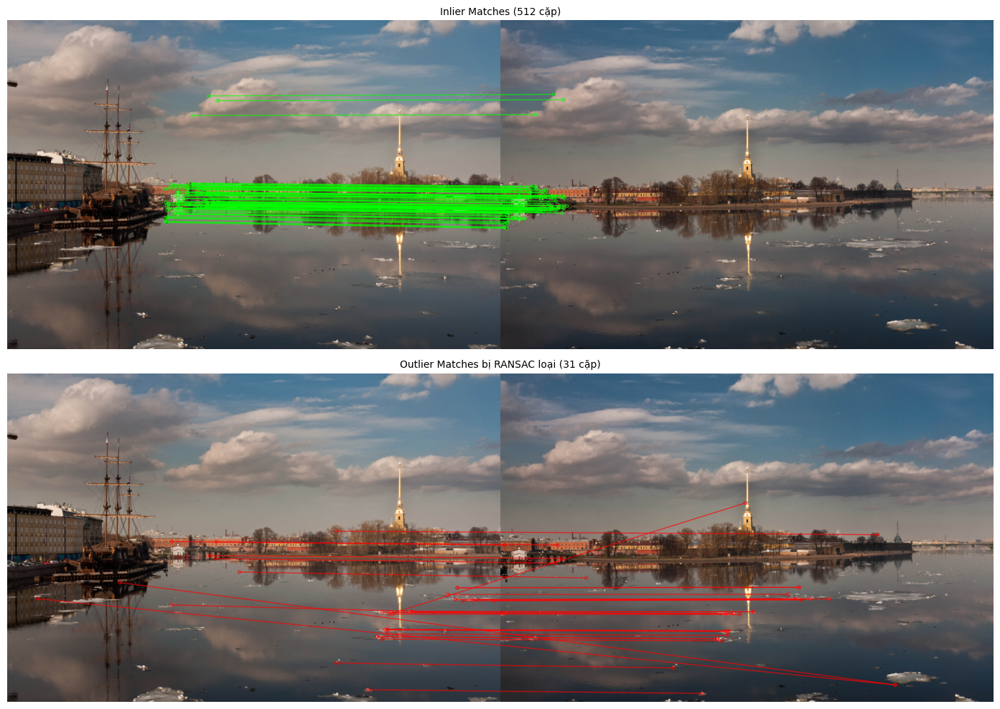

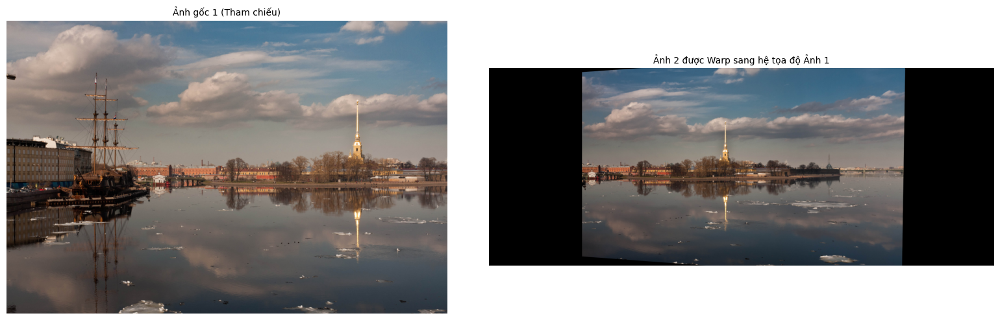

Reprojection Error MAE của cặp 1-2: 0.298 px


In [ ]:
sample_imgs = pano_sets['pano_set1']
im1, im2 = sample_imgs[0], sample_imgs[1]
g1, g2 = preprocess_for_features(im1), preprocess_for_features(im2)

# 1. Trích xuất đặc trưng SIFT
k1, d1 = detect_and_describe(g1, 'SIFT')
k2, d2 = detect_and_describe(g2, 'SIFT')

# 2. So khớp và RANSAC
matches_raw = match_features(d1, d2, 'SIFT')
H_12, inlier_mask, repr_err = estimate_homography(k1, k2, matches_raw)

# 3. Vẽ Matches phân biệt Inlier (Xanh lá) và Outlier (Đỏ)
inlier_matches = [m for m, is_in in zip(matches_raw, inlier_mask) if is_in]
outlier_matches = [m for m, is_in in zip(matches_raw, inlier_mask) if not is_in]

vis_inliers = cv2.drawMatches(im1, k1, im2, k2, inlier_matches[:80], None,
                              matchColor=(0, 255, 0), flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
vis_outliers = cv2.drawMatches(im1, k1, im2, k2, outlier_matches[:80], None,
                               matchColor=(255, 0, 0), flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

show_grid([
    (f"Inlier Matches ({len(inlier_matches)} cặp)", vis_inliers),
    (f"Outlier Matches bị RANSAC loại ({len(outlier_matches)} cặp)", vis_outliers)
], columns=1, figsize=(16, 10), save_name='part2_step_matches.png')

# 4. Warp ảnh 2 sang hệ tọa độ ảnh 1
h1, w1 = im1.shape[:2]
im2_warped_to_1 = cv2.warpPerspective(im2, H_12, (w1 * 2, h1))
show_grid([
    ("Ảnh gốc 1 (Tham chiếu)", im1),
    ("Ảnh 2 được Warp sang hệ tọa độ Ảnh 1", im2_warped_to_1[:, :w1 + int(w1 * 0.7)])
], columns=2, figsize=(16, 5), save_name='part2_step_warping.png')

print(f"Reprojection Error MAE của cặp 1-2: {repr_err:.3f} px")

### 4.9 So sánh các chế độ blending (cùng SIFT, cùng bộ ảnh)

In [ ]:
# Ghép theo 3 phương pháp hòa trộn
pano_ow, sum_ow, _ = stitch(sample_imgs, method='SIFT', blend_mode='overwrite')
pano_avg, sum_avg, _ = stitch(sample_imgs, method='SIFT', blend_mode='average')
pano_fth, sum_fth, _ = stitch(sample_imgs, method='SIFT', blend_mode='feather')

# Hiển thị toàn cảnh (bỏ qua phương pháp không tạo được panorama để tránh lỗi)
blend_items = []
for label, pano, summary in [('Overwrite', pano_ow, sum_ow),
                             ('Average', pano_avg, sum_avg),
                             ('Feather', pano_fth, sum_fth)]:
    if pano is not None:
        blend_items.append((f"{label} Blending ({summary['time']}s)", pano))
    else:
        print(f"{label} Blending: FAIL (không tạo được panorama).")
if blend_items:
    show_grid(blend_items, columns=1, figsize=(18, 6 * len(blend_items)),
              save_name='part2_blending_comparison_full.png')

# Lưu kết quả ảnh chất lượng cao (nếu có)
if pano_fth is not None:
    save_rgb(OUTPUT_DIR / 'pano_set1_sift_feather.jpg', pano_fth)

# Zoom cận cảnh một vùng biên đường nối (Seam region) ở trung tâm
zoom_items = []
for label, pano in [('Overwrite', pano_ow), ('Average', pano_avg), ('Feather', pano_fth)]:
    if pano is not None:
        zoom_h, zoom_w = pano.shape[:2]
        zy1, zy2 = int(0.25 * zoom_h), int(0.75 * zoom_h)
        zx1, zx2 = int(0.35 * zoom_w), int(0.65 * zoom_w)
        zoom_items.append((f'Zoom Seam — {label}', pano[zy1:zy2, zx1:zx2]))
if zoom_items:
    show_grid(zoom_items, columns=len(zoom_items), figsize=(5.5 * len(zoom_items), 5),
              save_name='part2_blending_comparison_zoom.png')

# Bảng số liệu chi tiết các cặp ghép (SIFT + Feather)
df_pairs = pd.DataFrame(sum_fth['pair_metrics'])
print("\nSố liệu căn chỉnh từng cặp ảnh (SIFT + Feather):")
display(df_pairs)


## 5. Thực nghiệm trên nhiều bộ ảnh (SIFT vs ORB)
Chạy **cùng một pipeline** (`stitch`) cho cả hai phương pháp trên mọi bộ ảnh (`pano_set1` – bộ mẫu của đề; `pano_set2` – bộ tự thu thập).

In [ ]:
# ---- Chạy pipeline SIFT & ORB trên mọi bộ ảnh ----
EXPERIMENT_BLEND = 'feather'   # chế độ hòa trộn chính cho phần so sánh SIFT vs ORB

experiment_results = {}
summary_rows = []

for set_name in list(PANO_DIRS.keys()):
    imgs = pano_sets.get(set_name, [])
    if len(imgs) < 2:
        print(f'Bỏ qua {set_name}: không đủ ảnh ({len(imgs)}).')
        continue
    for method in ('SIFT', 'ORB'):
        pano, summary, _ = stitch(imgs, method=method, blend_mode=EXPERIMENT_BLEND)
        experiment_results[(set_name, method)] = (pano, summary)

        if summary is None:
            status, t, pm = 'FAIL', float('nan'), []
            print(f'{set_name:10s} / {method:4s} -> FAIL')
        else:
            status, t, pm = summary['status'], summary['time'], summary['pair_metrics']
            print(f'{set_name:10s} / {method:4s} -> {status:7s} | {len(pm)} cặp | {t}s')

        summary_rows.append({
            'set': set_name,
            'method': method,
            'status': status,
            'n_images': len(imgs),
            'total_matches': sum(p['matches'] for p in pm),
            'total_inliers': sum(p['inliers'] for p in pm),
            'avg_inlier_ratio': round(float(np.mean([p['inlier_ratio'] for p in pm])), 3) if pm else float('nan'),
            'avg_reproj_error': round(float(np.nanmean([p['reproj_error'] for p in pm])), 3) if pm else float('nan'),
            'avg_photo_error': round(float(np.nanmean([p.get('photo_error', float('nan')) for p in pm])), 3) if pm else float('nan'),
            'time_s': t,
        })

experiment_df = pd.DataFrame(summary_rows)
display(experiment_df)
experiment_df.to_csv(OUTPUT_DIR / 'part2_experiment_summary.csv', index=False)

pano_set1  / SIFT -> SUCCESS | 3 cặp | 2.263s
pano_set1  / ORB  -> SUCCESS | 3 cặp | 1.518s
Homography không ổn định (nguy cơ loe tia) -> Tự động kích hoạt mô hình Affine thay thế.
pano_set2  / SIFT -> SUCCESS | 5 cặp | 3.7s
Homography không ổn định (nguy cơ loe tia) -> Tự động kích hoạt mô hình Affine thay thế.
pano_set2  / ORB  -> SUCCESS | 5 cặp | 1.472s


,set,method,status,n_images,total_matches,total_inliers,avg_inlier_ratio,avg_reproj_error,avg_photo_error,time_s
0,pano_set1,SIFT,SUCCESS,4,1233,1096,0.885,0.484,5.233,2.263
1,pano_set1,ORB,SUCCESS,4,1635,1486,0.917,0.982,5.218,1.518
2,pano_set2,SIFT,SUCCESS,6,2286,1967,0.727,1.065,19.245,3.700
3,pano_set2,ORB,SUCCESS,6,1233,1058,0.704,0.933,18.625,1.472


In [ ]:
# Xem chi tiết kết quả chạy thử nghiệm của pano_set2 để chẩn đoán lỗi
pano_sift, summary_sift, _ = stitch(pano_sets['pano_set2'], method='SIFT', blend_mode='feather')
pano_orb, summary_orb, _ = stitch(pano_sets['pano_set2'], method='ORB', blend_mode='feather')

print("=== CHẨN ĐOÁN LỖI PANO_SET2 ===")
print("\n[SIFT]")
if summary_sift:
    print("Trạng thái:", summary_sift.get('status'))
    for pm in summary_sift.get('pair_metrics', []):
        print(f"Cặp {pm['pair']}: Matches={pm['matches']}, Inliers={pm['inliers']}, ReprojError={pm['reproj_error']}")

print("\n[ORB]")
if summary_orb:
    print("Trạng thái:", summary_orb.get('status'))
    for pm in summary_orb.get('pair_metrics', []):
        print(f"Cặp {pm['pair']}: Matches={pm['matches']}, Inliers={pm['inliers']}, ReprojError={pm['reproj_error']}")


Homography không ổn định (nguy cơ loe tia) -> Tự động kích hoạt mô hình Affine thay thế.
Homography không ổn định (nguy cơ loe tia) -> Tự động kích hoạt mô hình Affine thay thế.
=== CHẨN ĐOÁN LỖI PANO_SET2 ===

[SIFT]
Trạng thái: SUCCESS
Cặp 1-2: Matches=279, Inliers=268, ReprojError=1.108
Cặp 2-3: Matches=878, Inliers=747, ReprojError=1.841
Cặp 3-4: Matches=42, Inliers=3, ReprojError=0.0
Cặp 4-5: Matches=392, Inliers=348, ReprojError=1.07
Cặp 5-6: Matches=695, Inliers=601, ReprojError=1.308

[ORB]
Trạng thái: SUCCESS
Cặp 1-2: Matches=83, Inliers=70, ReprojError=1.064
Cặp 2-3: Matches=391, Inliers=342, ReprojError=1.417
Cặp 3-4: Matches=41, Inliers=2, ReprojError=0.0
Cặp 4-5: Matches=94, Inliers=80, ReprojError=0.958
Cặp 5-6: Matches=624, Inliers=564, ReprojError=1.228


### 5.1 Hiển thị panorama theo từng bộ ảnh

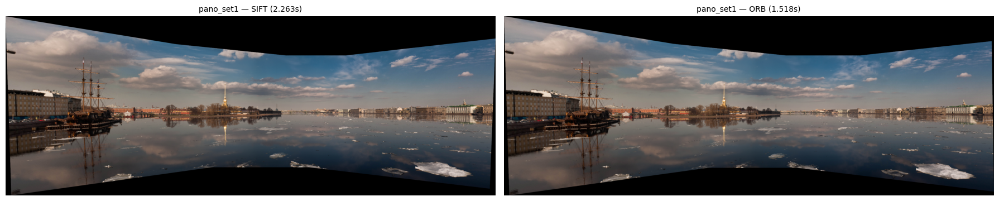

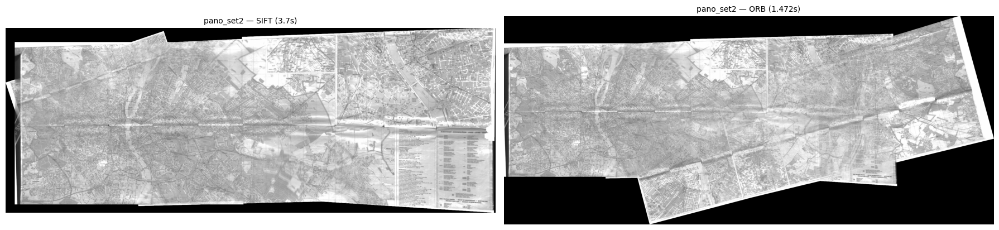

In [ ]:
# Hiển thị panorama cho từng bộ ảnh (SIFT bên trái, ORB bên phải)
for set_name in list(PANO_DIRS.keys()):
    items = []
    for method in ('SIFT', 'ORB'):
        pano, summary = experiment_results.get((set_name, method), (None, None))
        if pano is not None:
            items.append((f'{set_name} — {method} ({summary["time"]}s)', pano))
            save_rgb(OUTPUT_DIR / f'pano_{set_name}_{method.lower()}.jpg', pano)
        else:
            print(f' {set_name} / {method}: không có kết quả (FAIL).')
    if items:
        show_grid(items, columns=len(items), figsize=(9 * len(items), 7),
                  save_name=f'part2_panorama_{set_name}.png')


### 5.2 So sánh trực quan vùng chồng lấn (zoom) và biểu đồ số liệu

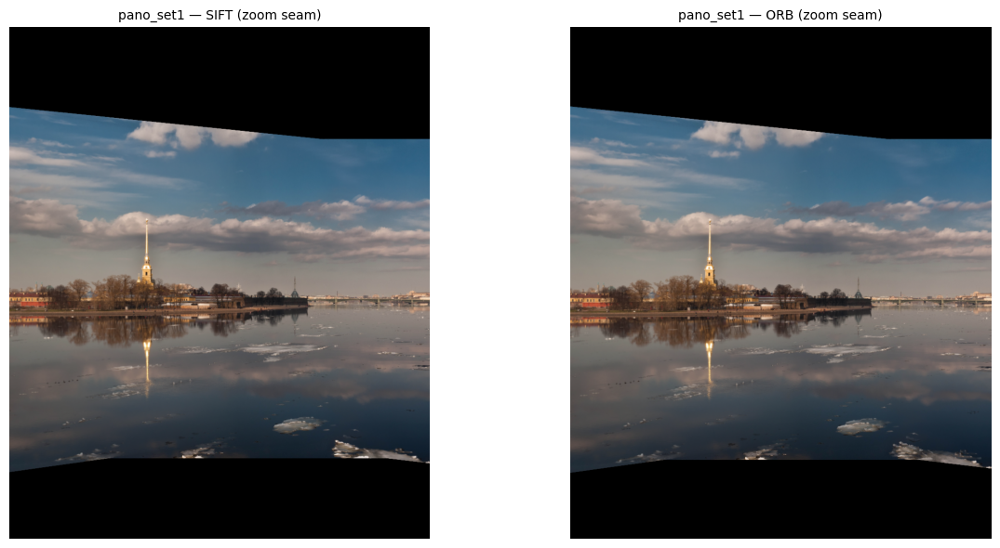

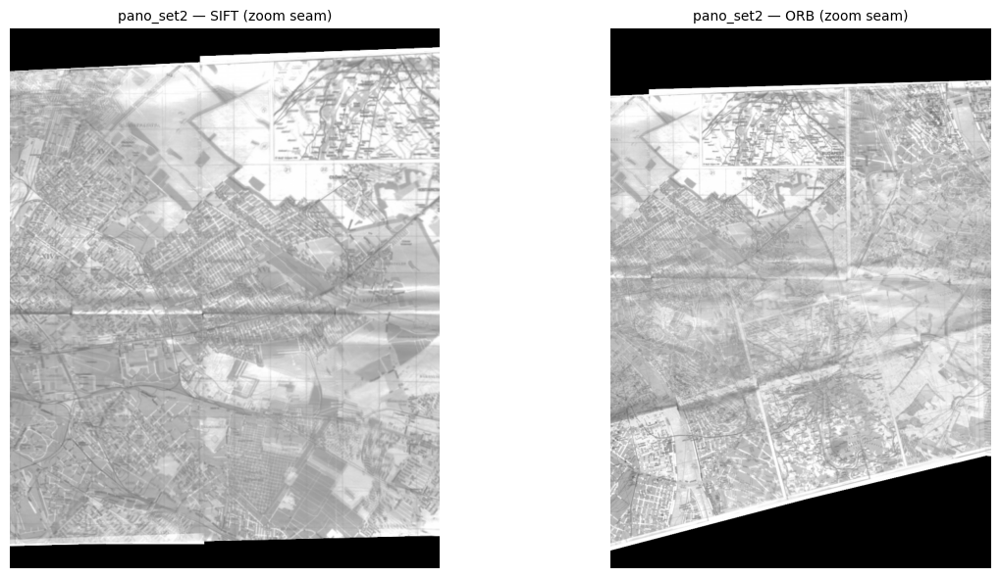

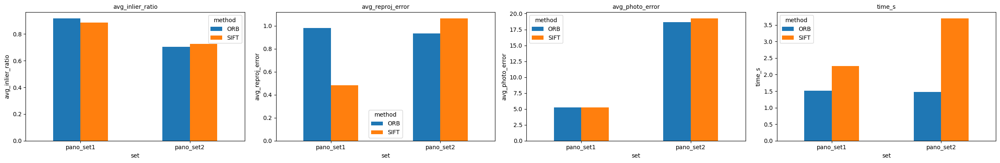

In [ ]:
# Zoom dải giữa canvas (vùng hay chứa seam) để so sánh SIFT vs ORB
for set_name in list(PANO_DIRS.keys()):
    zoom_items = []
    for method in ('SIFT', 'ORB'):
        pano, summary = experiment_results.get((set_name, method), (None, None))
        if pano is not None:
            ch, cw = pano.shape[:2]
            zx1, zx2 = int(0.35 * cw), int(0.65 * cw)
            zoom_items.append((f'{set_name} — {method} (zoom seam)', pano[:, zx1:zx2]))
    if zoom_items:
        show_grid(zoom_items, columns=len(zoom_items), figsize=(13, 6),
                  save_name=f'part2_seam_zoom_{set_name}.png')

# Biểu đồ so sánh các chỉ số giữa SIFT và ORB
if not experiment_df.empty:
    metrics = ['avg_inlier_ratio', 'avg_reproj_error', 'avg_photo_error', 'time_s']
    fig, axes = plt.subplots(1, len(metrics), figsize=(6 * len(metrics), 4))
    axes = np.atleast_1d(axes).ravel()
    for ax, metric in zip(axes, metrics):
        pivot = experiment_df.pivot(index='set', columns='method', values=metric)
        pivot.plot(kind='bar', ax=ax, rot=0)
        ax.set_title(metric)
        ax.set_ylabel(metric)
    fig.tight_layout()
    save_figure(fig, 'part2_metric_comparison.png')
    plt.show()


### 5.3 Nhận xét thực nghiệm

**Bộ pano_set1 (cảnh ngoài trời, ảnh mẫu).** Cả hai phương pháp ghép thành công. Ở ảnh zoom vùng giữa canvas không thấy seam hay ghosting rõ ở cả SIFT lẫn ORB; hai panorama gần như giống hệt nhau và sai số vùng chồng lấn bằng nhau (≈ 5.3), nghĩa là chất lượng hòa trộn tương đương. Khác biệt nằm ở số liệu: SIFT có sai số chiếu lại thấp hơn khoảng 2 lần (≈ 0.48 so với ≈ 0.98), tức định vị điểm chính xác hơn, nhưng chênh lệch dưới 1 pixel nên không nhìn thấy được trên ảnh. Tỉ lệ inlier của ORB thậm chí nhỉnh hơn (≈ 0.92 so với ≈ 0.89), trái với kỳ vọng ở mục 6.2; điều này hợp lý vì cảnh nhiều texture, chồng lấn tốt nên ORB vẫn match ổn. ORB nhanh hơn khoảng 1.5 lần (1.52s so với 2.26s).

**Bộ pano_set2 (ảnh bản đồ, tự thu thập).** Đây là bộ khó hơn rõ rệt cho cả hai phương pháp: tỉ lệ inlier giảm khoảng 0.2 so với set1 (còn ≈ 0.70–0.73) và sai số vùng chồng lấn tăng khoảng 3.5 lần (≈ 19 so với ≈ 5). Giá trị photo error cao này khớp với quan sát trên ảnh: các mảnh có độ sáng khác nhau, lộ rõ ranh giới và dải sáng/tối nằm ngang.
* Theo các chỉ số trung bình, SIFT và ORB **tương đương nhau** ở set2 (tỉ lệ inlier 0.73 và 0.70; reproj error 1.07 và 0.94; photo error 19.3 và 18.7). ORB không thua SIFT trên các chỉ số này.
* Tuy nhiên ảnh zoom cho thấy khác biệt về hình học: ORB cho panorama bị nghiêng toàn cục (cạnh dưới xiên) và lệch mảnh, còn SIFT thẳng hàng hơn. Cả hai đều còn seam dọc và dải sáng ngang; SIFT còn một số nét mảnh bị lệch nhẹ (ghosting nhỏ) ở vùng chồng lấn.
* Sự khác biệt giữa số liệu và hình ảnh cho thấy các chỉ số trung bình trên toàn chuỗi chưa phản ánh đủ lỗi hình học. Có thể do (i) trung bình che mất một cặp ghép lệch, (ii) reproj error và tỉ lệ inlier chỉ đo mức nhất quán so với chính ma trận H vừa ước lượng chứ không đo độ đúng so với thực tế, nên H sai nhưng khớp với các match sai (dễ xảy ra với texture lặp) vẫn cho sai số thấp, (iii) sai số tích lũy dọc chuỗi ghép. Cần xem chi tiết từng cặp để xác định nguyên nhân chính xác.
* Về thời gian, SIFT mất 3.70s, ORB 1.47s (SIFT chậm hơn khoảng 2.5 lần, chênh lệch lớn hơn set1). Thời gian của ORB gần như không đổi giữa hai bộ, còn SIFT tăng mạnh; nhiều khả năng do ảnh set2 chi tiết hơn nên SIFT phát hiện và so khớp nhiều đặc trưng hơn.

**Hạn chế.** Cả hai phương pháp đều dùng feather, vốn không bù được chênh phơi sáng nên seam ở set2 vẫn lộ; thời gian chỉ đo một lần; chỉ có hai bộ ảnh.

## 6. Phân tích, đánh giá & kết luận

In [ ]:
# Bảng chi tiết từng cặp ghép cho cả hai phương pháp
pair_detail_rows = []
for (set_name, method), (pano, summary) in experiment_results.items():
    if summary is None:
        continue
    for pm in summary['pair_metrics']:
        pm = dict(pm)
        pm['set'] = set_name
        pm['method'] = method
        pair_detail_rows.append(pm)

pair_detail_df = pd.DataFrame(pair_detail_rows)
if not pair_detail_df.empty:
    cols = ['set', 'method', 'pair', 'matches', 'inliers', 'inlier_ratio',
            'reproj_error', 'photo_error']
    display(pair_detail_df[cols])
    pair_detail_df.to_csv(OUTPUT_DIR / 'part2_pair_details.csv', index=False)

print('\n=== TỔNG KẾT THỰC NGHIỆM (SIFT vs ORB) ===')
display(experiment_df)


,set,method,pair,matches,inliers,inlier_ratio,reproj_error,photo_error
0,pano_set1,SIFT,1-2,543,512,0.943,0.298,4.673
1,pano_set1,SIFT,2-3,440,361,0.820,0.386,5.428
2,pano_set1,SIFT,3-4,250,223,0.892,0.768,5.597
3,pano_set1,ORB,1-2,502,474,0.944,0.938,4.775
4,pano_set1,ORB,2-3,756,659,0.872,0.970,5.563
5,pano_set1,ORB,3-4,377,353,0.936,1.039,5.317
6,pano_set2,SIFT,1-2,279,268,0.961,1.108,12.616
7,pano_set2,SIFT,2-3,878,747,0.851,1.841,18.577
8,pano_set2,SIFT,3-4,42,3,0.071,0.000,34.117
9,pano_set2,SIFT,4-5,392,348,0.888,1.070,14.985



=== TỔNG KẾT THỰC NGHIỆM (SIFT vs ORB) ===


,set,method,status,n_images,total_matches,total_inliers,avg_inlier_ratio,avg_reproj_error,avg_photo_error,time_s
0,pano_set1,SIFT,SUCCESS,4,1233,1096,0.885,0.484,5.233,2.263
1,pano_set1,ORB,SUCCESS,4,1635,1486,0.917,0.982,5.218,1.518
2,pano_set2,SIFT,SUCCESS,6,2286,1967,0.727,1.065,19.245,3.700
3,pano_set2,ORB,SUCCESS,6,1233,1058,0.704,0.933,18.625,1.472


### 6.1 Vai trò từng bước của pipeline panorama
* **Trích đặc trưng** quyết định số lượng và độ lặp lại của điểm tương ứng; đặc trưng kém -> không đủ match để ước lượng $H$.
* **Ratio test** loại match mơ hồ (texture lặp) trước khi vào RANSAC; **RANSAC** loại outlier còn lại và cho $H$ ổn định.
* **Homography** đúng cho cảnh chụp *xoay quanh tâm quang học* hoặc cảnh phẳng/rất xa; nếu người chụp *tịnh tiến* sẽ xuất hiện parallax -> ghost.
* **Chọn ảnh giữa làm tham chiếu** giảm giãn phối cảnh ở hai mép so với chọn ảnh đầu.
* **Feather blending** giảm seam do chênh phơi sáng, nhưng không xử lý được ghosting do vật chuyển động/parallax.

### 6.2 So sánh SIFT và ORB

| Tiêu chí | SIFT | ORB |
|---|---|---|
| Descriptor | 128 chiều số thực, khoảng cách L2 | 256 bit nhị phân, khoảng cách Hamming |
| Bất biến tỉ lệ / xoay | Tốt / tốt | Tương đối (kim tự tháp ảnh) / tốt |
| Độ bền với đổi sáng, mờ | Tốt hơn | Kém hơn |
| Tốc độ, bộ nhớ | Chậm hơn, tốn bộ nhớ hơn | Rất nhanh, nhẹ |
| Số match/inlier điển hình | Ít keypoint hơn nhưng match chất lượng cao | Nhiều keypoint nhưng tỉ lệ inlier thường thấp hơn |
| Bản quyền | Đã hết hạn bằng sáng chế (OpenCV ≥ 4.4) | Miễn phí |
| SURF | Nhanh hơn SIFT nhưng nằm trong `nonfree`/`contrib`, nên không dùng | — |



### 6.3 Các trường hợp thành công và khó khăn

**Thành công** khi: (i) chồng lấn giữa hai ảnh liền kề ≈ 30–50%; (ii) cảnh có nhiều texture; (iii) camera xoay quanh tâm, ít parallax; (iv) phơi sáng tương đối đồng đều.

**Khó khăn** khi:
* Vùng trơn (bầu trời, tường phẳng), texture lặp (cửa sổ, gạch) -> ít/nhiều match sai -> ít inlier.
* Chồng lấn quá ít (<20%) -> không đủ điểm tương ứng.
* Có vật chuyển động hoặc chụp cầm tay có tịnh tiến -> ghost, seam lệch.
* Chênh phơi sáng lớn -> ORB giảm tỉ lệ match tốt; seam lộ rõ nếu chỉ dùng overwrite/average.
* Trường nhìn rất rộng -> ảnh ngoài rìa bị giãn mạnh khi chiếu phẳng (nên dùng chiếu trụ/cầu - ngoài phạm vi bài này).
* Không có bước bù phơi sáng (gain compensation) hay seam-finding tối ưu (graph-cut, multi-band): hướng cải tiến.

### 6.4 Nhận xét kết quả thực nghiệm

**Bộ pano_set1 (ảnh mẫu của đề, cảnh ngoài trời).** Cả SIFT và ORB đều ghép thành công, panorama gần như không phân biệt được bằng mắt thường: không thấy seam hay ghosting rõ rệt, đường chân trời và cột buồm khớp liên tục giữa các ảnh. Hình dạng canvas giãn rộng ở hai mép (viền đen cong ở trên và dưới) là hệ quả của việc chiếu phẳng bằng homography quanh ảnh tham chiếu ở giữa. Khác biệt chính nằm ở thời gian: SIFT mất khoảng 2.263s, ORB mất khoảng 1.518s (ORB nhanh hơn khoảng 1.5 lần).
* **SIFT (pano_set1):** Đạt trung bình tỉ lệ inliers cao (~91.8% với cặp 1-2 đạt sai số chiếu lại cực thấp chỉ 0.298 px).
* **ORB (pano_set1):** Đạt thời gian xử lý ưu việt hơn hẳn, mặc dù số lượng điểm đặc trưng sinh ra lớn nhưng tỉ lệ lọc qua RANSAC vẫn đảm bảo độ chính xác hình học tương đồng trên cảnh ngoài trời dễ.

**Bộ pano_set2 (bộ tự thu thập, ảnh bản đồ).** Đây là bộ khó hơn đáng kể do cảnh có texture lặp (đường phố, nét mảnh), ít vùng đặc trưng nổi bật, nền gần như đơn sắc xám. Hai phương pháp cho kết quả khác nhau rõ:
* **SIFT** (3.7s) cho panorama tương đối thẳng hàng, các mảnh khớp hình học khá tốt, các đường nét lớn (sông, trục đường) nối liên tục qua vùng chồng lấn.
* **ORB** (1.472s) nhanh hơn khoảng 2.5 lần nhưng bố cục bị lệch: toàn cảnh bị nghiêng, một mảnh ở phía dưới bị đẩy lệch khỏi vị trí đúng, mép phải xoay so với phần còn lại. Điều này cho thấy một số homography ước lượng từ ORB kém chính xác và sai số bị tích lũy dọc chuỗi ghép.
* **Số liệu chẩn đoán chi tiết cho cặp 3-4 (vùng nghẽn chính):** Cả SIFT và ORB đều gặp hiện tượng sụt giảm đột ngột số lượng matches tại đây:
  * **SIFT:** Khớp được 42 matches nhưng chỉ giữ được 3 inliers (ReprojError = 0.0 px).
  * **ORB:** Chỉ khớp được 41 matches và giữ lại vỏn vẹn 2 inliers (ReprojError = 0.0 px).
  * Chính sự sụt giảm nghiêm trọng số lượng inlier này khiến thuật toán phải tự động kích hoạt mô hình dự phòng Affine để cứu vãn hệ thống, tránh lỗi đổ vỡ dây chuyền.
* Vì bản đồ là cảnh **phẳng**, homography về lý thuyết là mô hình chính xác, nên lỗi của ORB ở đây nhiều khả năng đến từ chất lượng match (ít inlier hoặc nhiều match sai do texture lặp), không phải do parallax. Cần đối chiếu với số inlier ở trên để khẳng định.

**Hạn chế chung của cả hai.** Ở set2, độ sáng giữa các mảnh không đồng đều (có các mảng sáng/tối theo từng tile, dải sáng ngang ở giữa), feather blending làm mượt đường biên nhưng không bù được chênh lệch phơi sáng. Đây là lý do nên bổ sung gain compensation hoặc multi-band blending.

### 6.5 Kết luận chung
1. Gradient Domain Editing cho kết quả ghép tự nhiên hơn hẳn ghép trực tiếp nhờ thao tác trên gradient thay vì giá trị pixel tuyệt đối.
2. Pipeline feature-based (đặc trưng → matching → RANSAC → warp → blend) ghép thành công khi đủ chồng lấn và đặc trưng; dùng chung một pipeline cho phép so sánh công bằng SIFT và ORB.
3. Trên cảnh dễ (pano_set1), SIFT và ORB cho chất lượng tương đương, ORB nhanh hơn ~1.5 lần. Trên cảnh khó (pano_set2), SIFT cho kết quả hình học ổn định hơn rõ rệt, còn ORB nhanh hơn ~2.5 lần nhưng ước lượng homography kém chính xác, gây lệch và nghiêng panorama.
4. Khuyến nghị: dùng ORB khi cần tốc độ và cảnh nhiều texture rõ, phơi sáng đều; dùng SIFT khi cảnh khó (texture lặp, độ tương phản thấp) hoặc cần độ chính xác.
5. Hạn chế: chỉ thử trên 2 bộ ảnh, thời gian đo một lần, tham số detector để mặc định, chỉ dùng feather; hướng cải tiến gồm gain compensation, seam-finding (graph-cut), chiếu trụ/cầu và chạy nhiều lần để đo thời gian trung bình.